# Tarea 2 – Parte 1: Corpus y extracción (OCR + ASR)

**Pregunta guía:** ¿Pueden convertirse documentos escaneados y entrevistas en audio en un archivo de texto estructurado y buscable?

## 1.1. Configuración inicial

*Registrar en la primera celda Markdown la fecha de extracción, las fuentes y licencias, y las versiones de PaddleOCR y del modelo ASR (usen los entornos de las sesiones: uv sync --group docai y uv sync --group audio).*

- **Fecha de extracción:** 22 y 23 de octubre de 2026 (OCR el 22; transcripción y diarización el 22 y el 23)
- **Fuentes y licencias:** 8 páginas de mi trabajo de licenciatura, 9 fotos de mis apuntes de clase de estadística y cerámica (documentos propios, uso autorizado), 8 fotos de la publicación *Estudio de Gobiernos Locales 2016* de SERVIR ([PDF oficial](https://cdn.www.gob.pe/uploads/document/file/1206414/Estudio-de-Gobiernos-Locales-2016-SERVIR.pdf)); 37 minutos de grabaciones propias (conversaciones con mi hermana, con un compañero de trabajo y con mi familia), con el consentimiento de todas las personas que hablan. Detalle por archivo en `datos/fuentes.csv`.
- **Versiones:** Python 3.12.14 · PaddleOCR 3.7.0 (PaddlePaddle 3.3.1, modelos PP-OCRv6 medium, `lang="es"`) · faster-whisper 1.2.1 (modelo `small`, int8, CPU) · pyannote-audio 4.0.7 · torch 2.14.1

In [1]:
import os
import re
import json
import time
from importlib.metadata import version
from pathlib import Path

# Se evita que PaddleOCR revise la conexión con cada servidor de modelos (va antes de importarlo)
os.environ["PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK"] = "True"

import torch  # Se importa antes que paddleocr: en Windows, al revés, torch falla (WinError 127)
import pandas as pd
import numpy as np
import soundfile as sf
from paddleocr import PaddleOCR
from faster_whisper import WhisperModel, decode_audio

for paquete in ["paddleocr", "paddlepaddle", "faster-whisper", "pyannote-audio", "torch"]:
    print(f"{paquete}: {version(paquete)}")


c:\Users\LENOVO\Documents\GitHub\Python_intermedio\tarea_2\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


paddleocr: 3.7.0
paddlepaddle: 3.3.1
faster-whisper: 1.2.1
pyannote-audio: 4.0.7
torch: 2.14.1


In [2]:
# Se crea el lector OCR en español (modelos PP-OCRv6).
# enable_mkldnn=False evita el error de oneDNN en procesadores Intel.
# El clasificador de orientación endereza las fotos giradas 90°, y el texto se busca en una copia
# de máximo 1600 px para que las fotos de 12 MP no tarden más de 10 minutos cada una en esta laptop.
ocr = PaddleOCR(
    lang="es",
    enable_mkldnn=False,
    use_doc_orientation_classify=True,    # se endereza la página si está girada
    use_doc_unwarping=False,              # no se "aplana" la hoja
    use_textline_orientation=False,       # no se gira cada línea
    text_det_limit_type="max",
    text_det_limit_side_len=1600,         # lado mayor de la copia donde se busca el texto
)

c:\Users\LENOVO\Documents\GitHub\Python_intermedio\tarea_2\.venv\Lib\site-packages\paddle\utils\cpp_extension\extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)
Creating model: ('PP-LCNet_x1_0_doc_ori', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\LENOVO\.paddlex\official_models\PP-LCNet_x1_0_doc_ori`.
Creating model: ('PP-OCRv6_medium_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\LENOVO\.paddlex\official_models\PP-OCRv6_medium_det`.
Creating model: ('PP-OCRv6_medium_rec', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\LENOVO\.paddlex\official_models\PP-O

In [3]:
# Se carga faster-whisper "small" en CPU con int8 (la misma configuración de la línea base de la Parte 2)
modelo_asr = WhisperModel("small", device="cpu", compute_type="int8")

## 1.2. OCR (Sesión 10):

*Extraer texto de los 25 documentos con PaddleOCR (impresos, fotos y manuscritos),guardando respaldo crudo y recortes en datos/raw/documentos/. Documentar parámetros (idioma,preprocesamiento).*

A continuación, se describen los documentos seleccionados:

1. 8 imágenes imprenta: Corresponde al documento de mi titulación.
2. 8 fotos de un documento imprenta: Corresponde al docuemento de SERVIR "Estudio de gobiernos locales 2016: Principales hallazgos sobre los puestos con los que cuentan y las personas que los ocupan" (https://repositorio.servir.gob.pe/item/025583e3-60dc-4f56-91d3-9160138f24b8). En la página 4, indica que se puede usar este documento con fines de estudios privados, siempre que se reconozca la autoría de SERVIR.
3. 9 fotos de manuscritos: Corresponde a mis apuntes de clase de estadística, matemática y cerámica.

**Parámetros del OCR:** español (`lang="es"`, modelos PP-OCRv6 medium); clasificador de orientación activado para enderezar las fotos giradas 90°; el texto se busca en una copia de máximo 1600 px, porque en esta laptop (CPU de 2 núcleos) cada foto de 12 MP tardaba de 9 a 13 minutos y así tarda cerca de 3; oneDNN desactivado por un error de PaddlePaddle en procesadores Intel. No se aplica otro preprocesamiento. Los respaldos crudos (JSON con texto, cajas y confianza, e imagen con las cajas detectadas) se guardan en `datos/raw/documentos/ocr/`.

In [4]:
# Se listan los 25 documentos y se asigna su tipo según el número: 001–008 impresos, 009–016 fotos y 017–025 manuscritos
CARPETA_DOCS = Path("datos/raw/documentos")
CARPETA_OCR = CARPETA_DOCS / "ocr"          # respaldo crudo del OCR
CARPETA_OCR.mkdir(exist_ok=True)

def tipo_documento(numero):
    if numero <= 8:
        return "impreso"
    elif numero <= 16:
        return "foto"
    return "manuscrito"

archivos = sorted(CARPETA_DOCS.glob("doc_*.*"))
documentos = pd.DataFrame({"id": [f.stem for f in archivos], "archivo": [f.as_posix() for f in archivos]})
documentos["tipo"] = documentos["id"].str[-3:].astype(int).apply(tipo_documento)
documentos["tipo"].value_counts()

tipo
manuscrito    9
impreso       8
foto          8
Name: count, dtype: int64

**Excepción:** En la primera ejecución, el clasificador de orientación giró por error 180° la foto `doc_009` (inclinada y con una franja gris oscura arriba): su imagen enderezada quedó de cabeza y el texto salió ilegible (confianza media 0,64). Por eso, ese documento se procesa sin el clasificador; el resto de la configuración es la misma.

In [5]:
# Segundo lector, igual al primero pero sin el clasificador de orientación, solo para doc_009
SIN_ORIENTACION = ["doc_009"]
ocr_sin_orientacion = PaddleOCR(
    lang="es",
    enable_mkldnn=False,
    use_doc_orientation_classify=False,
    use_doc_unwarping=False,
    use_textline_orientation=False,
    text_det_limit_type="max",
    text_det_limit_side_len=1600,
)

Creating model: ('PP-OCRv6_medium_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\LENOVO\.paddlex\official_models\PP-OCRv6_medium_det`.
Creating model: ('PP-OCRv6_medium_rec', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\LENOVO\.paddlex\official_models\PP-OCRv6_medium_rec`.


In [6]:
# Se aplica el OCR a cada documento y se guarda su respaldo crudo (JSON e imágenes) en datos/raw/documentos/ocr/.
# Si un documento ya tiene su JSON, se lee de ahí y no se vuelve a procesar: así, al ejecutar de nuevo el notebook,
# no se repite la hora de OCR.
textos = []
for archivo in documentos["archivo"]:
    respaldo = CARPETA_OCR / f"{Path(archivo).stem}_res.json"
    if respaldo.exists():
        print(f"{Path(archivo).name}: se lee el respaldo")
    else:
        inicio = time.perf_counter()
        lector = ocr_sin_orientacion if Path(archivo).stem in SIN_ORIENTACION else ocr
        resultado = lector.predict(archivo)[0]
        resultado.save_to_json(CARPETA_OCR)
        resultado.save_to_img(CARPETA_OCR)
        print(f"{Path(archivo).name}: {time.perf_counter() - inicio:.0f} s")
    with open(respaldo, encoding="utf-8") as f:
        textos.append("\n".join(json.load(f)["rec_texts"]))

documentos["texto_ocr"] = textos
documentos["modelo_ocr"] = "PaddleOCR 3.7.0 (PP-OCRv6 medium, lang=es, orientación activada, detección máx. 1600 px)"
documentos.loc[documentos["id"].isin(SIN_ORIENTACION), "modelo_ocr"] = "PaddleOCR 3.7.0 (PP-OCRv6 medium, lang=es, orientación desactivada, detección máx. 1600 px)"

doc_001.png: se lee el respaldo
doc_002.png: se lee el respaldo
doc_003.png: se lee el respaldo
doc_004.png: se lee el respaldo
doc_005.png: se lee el respaldo
doc_006.png: se lee el respaldo
doc_007.png: se lee el respaldo
doc_008.png: se lee el respaldo
doc_009.jpg: se lee el respaldo
doc_010.jpg: se lee el respaldo
doc_011.jpg: se lee el respaldo
doc_012.jpg: se lee el respaldo
doc_013.jpg: se lee el respaldo
doc_014.jpg: se lee el respaldo
doc_015.jpg: se lee el respaldo
doc_016.jpg: se lee el respaldo
doc_017.jpg: se lee el respaldo
doc_018.jpg: se lee el respaldo
doc_019.jpg: se lee el respaldo
doc_020.jpg: se lee el respaldo
doc_021.jpg: se lee el respaldo
doc_022.jpg: se lee el respaldo
doc_023.jpg: se lee el respaldo
doc_024.jpg: se lee el respaldo
doc_025.jpg: se lee el respaldo


## 1.3. ASR (Sesión 13)

*Transcribir los 30 minutos con voz.py o equivalente: VAD, transcripción con faster-whisper, diarización en al menos un audio multihablante y exportación a CSV, SRT y TXT. Guardar losarchivos originales y salidas pesadas en datos/raw/audio/
(sin versionarlos en Git).*

A continuación se detallan los audios seleccionados:
1. 6 audios de conversación con mi hermana, referente a diversos temas. Ella me dio su consentimiento para grabar.
2. 8 audios de una conversación con un compañero de trabajo. Él me brindó su consentimiento para grabar. 
3. 12 audios de una conversación con mi hermana, mamá y papá. Todos dieron su consentimiento para grabar.

**Preparación de los clips:** cada grabación original (en `datos/raw/audio/originales/`) se convierte a 16 kHz mono, el formato que usan los modelos de ASR, y se guarda como `clip_XXX.wav`. Las grabaciones cortas quedan como un solo clip, y las conversación largas se dividieron: la converación con mi compañero de trabajo dura 10 minutos y se dividieron en 8 audios; la conversación con mi familia dura 18 minutos y se dividen en 12 audios.

In [7]:
# Se preparan los clips: cada original se convierte a 16 kHz mono y se guarda como clip_XXX.wav
CARPETA_AUDIO = Path("datos/raw/audio")
CARPETA_ORIGINALES = CARPETA_AUDIO / "originales"
SR = 16_000   # muestras por segundo

# Grabación original -> número de partes (el orden define el número de cada clip)
ORIGINALES = {
    "Grabación estándar 1.mp3": 1,
    "Grabación estándar 2.mp3": 1,
    "Grabación estándar 3.mp3": 1,
    "Grabación estándar 4.mp3": 1,
    "Grabación estándar 5.mp3": 1,
    "Grabación estándar 6.mp3": 1,
    "conversacion_trabajo.mp3": 8,
    "conversacion_familia.mp3": 12,    
}

def punto_de_corte(audio, segundo, ventana=10):
    """Busca el tramo de 0,1 s más silencioso a ±10 s del segundo indicado y devuelve su posición."""
    tramo = int(0.1 * SR)
    inicio = max(0, int((segundo - ventana) * SR))
    fin = min(len(audio), int((segundo + ventana) * SR))
    energias = [np.abs(audio[i:i + tramo]).mean() for i in range(inicio, fin - tramo, tramo)]
    return inicio + int(np.argmin(energias)) * tramo

def cortar_en_partes(audio, n_partes):
    """Divide el audio en n partes de duración parecida, cortando en pausas."""
    duracion = len(audio) / SR
    cortes = [0] + [punto_de_corte(audio, duracion * k / n_partes) for k in range(1, n_partes)] + [len(audio)]
    return [audio[a:b] for a, b in zip(cortes[:-1], cortes[1:])]

filas = []
for original, n_partes in ORIGINALES.items():
    audio = decode_audio(str(CARPETA_ORIGINALES / original), sampling_rate=SR)
    for parte in cortar_en_partes(audio, n_partes):
        id_clip = f"clip_{len(filas) + 1:03d}"
        archivo = CARPETA_AUDIO / f"{id_clip}.wav"
        sf.write(archivo, parte, SR)
        filas.append({"id": id_clip, "archivo_audio": archivo.as_posix(), "original": original,
                      "duracion_seg": round(len(parte) / SR, 1)})

clips = pd.DataFrame(filas)
print(f"{len(clips)} clips, {clips['duracion_seg'].sum() / 60:.1f} minutos")
clips


26 clips, 37.0 minutos


,id,archivo_audio,original,duracion_seg
0,clip_001,datos/raw/audio/clip_001.wav,Grabación estándar 1.mp3,53.7
1,clip_002,datos/raw/audio/clip_002.wav,Grabación estándar 2.mp3,74.5
2,clip_003,datos/raw/audio/clip_003.wav,Grabación estándar 3.mp3,133.0
3,clip_004,datos/raw/audio/clip_004.wav,Grabación estándar 4.mp3,93.7
4,clip_005,datos/raw/audio/clip_005.wav,Grabación estándar 5.mp3,72.9
5,clip_006,datos/raw/audio/clip_006.wav,Grabación estándar 6.mp3,105.5
6,clip_007,datos/raw/audio/clip_007.wav,conversacion_trabajo.mp3,75.3
7,clip_008,datos/raw/audio/clip_008.wav,conversacion_trabajo.mp3,80.6
8,clip_009,datos/raw/audio/clip_009.wav,conversacion_trabajo.mp3,79.8
9,clip_010,datos/raw/audio/clip_010.wav,conversacion_trabajo.mp3,67.8


**Transcripción:** faster-whisper `small` (int8, CPU) con VAD activado (el detector de voz Silero que trae faster-whisper, para que Whisper no "alucine" frases en los silencios) e idioma fijado en español. Por cada clip se guarda en `datos/raw/audio/transcripciones/` un JSON con los segmentos (inicio, fin y texto) y el tiempo de proceso, más su versión en SRT (subtítulos) y TXT.

In [8]:
# Carpeta del respaldo crudo de las transcripciones (JSON, SRT y TXT por clip)
CARPETA_ASR = CARPETA_AUDIO / "transcripciones"
CARPETA_ASR.mkdir(exist_ok=True)

def tiempo_srt(segundos):
    """Convierte segundos al formato de tiempo de los subtítulos SRT (HH:MM:SS,mmm)."""
    ms = int(round(segundos * 1000))
    h, ms = divmod(ms, 3_600_000)
    m, ms = divmod(ms, 60_000)
    s, ms = divmod(ms, 1000)
    return f"{h:02d}:{m:02d}:{s:02d},{ms:03d}"

def a_srt(segmentos):
    """Arma el texto SRT: número, intervalo de tiempo y texto de cada segmento."""
    bloques = [f"{i}\n{tiempo_srt(s['inicio'])} --> {tiempo_srt(s['fin'])}\n{s['texto']}\n"
               for i, s in enumerate(segmentos, 1)]
    return "\n".join(bloques)

# Se transcribe cada clip. Si ya tiene su JSON, se salta: así, al agregar grabaciones nuevas, solo se procesan esas.
for fila in clips.itertuples():
    respaldo = CARPETA_ASR / f"{fila.id}.json"
    if respaldo.exists():
        print(f"{fila.id}: se lee el respaldo")
        continue
    inicio = time.perf_counter()
    segmentos, info = modelo_asr.transcribe(fila.archivo_audio, language="es", vad_filter=True)
    segmentos = [{"inicio": round(s.start, 2), "fin": round(s.end, 2), "texto": s.text.strip()} for s in segmentos]
    segundos = time.perf_counter() - inicio
    resultado = {"id": fila.id, "idioma": info.language, "duracion_seg": fila.duracion_seg,
                 "segundos_proceso": round(segundos, 1), "segmentos": segmentos}
    respaldo.write_text(json.dumps(resultado, ensure_ascii=False, indent=1), encoding="utf-8")
    (CARPETA_ASR / f"{fila.id}.srt").write_text(a_srt(segmentos), encoding="utf-8")
    (CARPETA_ASR / f"{fila.id}.txt").write_text(" ".join(s["texto"] for s in segmentos), encoding="utf-8")
    print(f"{fila.id}: {fila.duracion_seg:.0f} s de audio en {segundos:.0f} s (RTF {segundos / fila.duracion_seg:.2f})")

clip_001: se lee el respaldo
clip_002: se lee el respaldo
clip_003: se lee el respaldo
clip_004: se lee el respaldo
clip_005: se lee el respaldo
clip_006: se lee el respaldo
clip_007: se lee el respaldo
clip_008: se lee el respaldo
clip_009: se lee el respaldo
clip_010: se lee el respaldo
clip_011: se lee el respaldo
clip_012: se lee el respaldo
clip_013: se lee el respaldo
clip_014: se lee el respaldo
clip_015: se lee el respaldo
clip_016: se lee el respaldo
clip_017: se lee el respaldo
clip_018: se lee el respaldo
clip_019: se lee el respaldo
clip_020: se lee el respaldo
clip_021: se lee el respaldo
clip_022: se lee el respaldo
clip_023: se lee el respaldo
clip_024: se lee el respaldo
clip_025: se lee el respaldo
clip_026: se lee el respaldo


In [9]:
# Se leen los respaldos y se agregan a la tabla de clips el idioma, el texto y el tiempo de proceso
def leer_respaldo(id_clip):
    with open(CARPETA_ASR / f"{id_clip}.json", encoding="utf-8") as f:
        return json.load(f)

respaldos = [leer_respaldo(i) for i in clips["id"]]
clips["idioma"] = [r["idioma"] for r in respaldos]
clips["texto_asr"] = [" ".join(s["texto"] for s in r["segmentos"]) for r in respaldos]
clips["segundos_asr"] = [r["segundos_proceso"] for r in respaldos]
clips["modelo_asr"] = "faster-whisper 1.2.1 small (int8, CPU, VAD activado, idioma es)"
clips[["id", "duracion_seg", "segundos_asr"]]

,id,duracion_seg,segundos_asr
0,clip_001,53.7,54.1
1,clip_002,74.5,85.6
2,clip_003,133.0,179.1
3,clip_004,93.7,175.7
4,clip_005,72.9,84.0
5,clip_006,105.5,115.3
6,clip_007,75.3,74.1
7,clip_008,80.6,86.1
8,clip_009,79.8,68.0
9,clip_010,67.8,57.5


**Diarización:** se calcula la "huella de voz" de cada segmento con el modelo WeSpeaker ResNet34 (`pyannote/wespeaker-voxceleb-resnet34-LM`, CC BY 4.0) y las huellas se agrupan con k-means, indicando el número de personas de cada grabación (2 en las conversaciones con la hermana de la autora y con el compañero de trabajo, 4 en la familiar). Primero se probó el método de `voz.py` (agrupación jerárquica con umbral automático), pero con estas grabaciones de celular detectaba hasta 13 hablantes en un clip de 4 personas. Los hablantes se numeran por orden de aparición: `[HABLANTE_1]` es quien habla primero. Limitaciones: un segmento de Whisper puede mezclar dos turnos, y los segmentos muy cortos ("Sí", "Ya") tienen huellas poco fiables.

Además, en los clips 001–006 había un televisor encendido: sus voces de fondo pueden confundirse con las de las hablantes. En los clips 007-014 también había un video reproduciéndose mientras conversaba con mi compañero. En los clips 015-026, hablaban 4 personas, por lo cual, era frecuente que se sobrepongan voces que hablan al mismo tiempo.

In [10]:
# Diarización: huella de voz por segmento (WeSpeaker) y agrupación con k-means según el número de personas
from pyannote.audio import Inference, Model
from sklearn.cluster import KMeans

modelo_voces = Inference(Model.from_pretrained("pyannote/wespeaker-voxceleb-resnet34-LM"), window="whole")

# Número de personas en cada grabación original
PERSONAS = {original: 2 for original in ORIGINALES}
PERSONAS["conversacion_familia.mp3"] = 4

def huellas_de_voz(audio, segmentos):
    """Una huella de voz (vector normalizado) por segmento; los tramos de menos de 0,5 s se completan con silencio."""
    filas = []
    for s in segmentos:
        tramo = audio[int(s["inicio"] * SR):int(s["fin"] * SR)]
        if len(tramo) < SR // 2:
            tramo = np.pad(tramo, (0, SR // 2 - len(tramo)))
        filas.append(modelo_voces({"waveform": torch.from_numpy(tramo).unsqueeze(0), "sample_rate": SR}))
    huellas = np.vstack(filas)
    return huellas / np.linalg.norm(huellas, axis=1, keepdims=True)

def diarizar(audio, segmentos, n_personas):
    """Agrupa los segmentos por voz y numera a los hablantes por orden de aparición."""
    if not segmentos:
        return []
    n = min(n_personas, len(segmentos))
    grupos = KMeans(n_clusters=n, n_init=10, random_state=42).fit_predict(huellas_de_voz(audio, segmentos))
    orden = {g: i + 1 for i, g in enumerate(dict.fromkeys(grupos))}
    return [orden[g] for g in grupos]

def texto_con_hablantes(segmentos, hablantes):
    """Une los segmentos y agrega la marca [HABLANTE_n] cada vez que cambia quien habla."""
    partes, anterior = [], None
    for s, h in zip(segmentos, hablantes):
        if h != anterior:
            partes.append(f"[HABLANTE_{h}]")
            anterior = h
        partes.append(s["texto"])
    return " ".join(partes)

textos, n_detectados = [], []
for fila in clips.itertuples():
    segmentos = leer_respaldo(fila.id)["segmentos"]
    audio = decode_audio(fila.archivo_audio, sampling_rate=SR)
    hablantes = diarizar(audio, segmentos, PERSONAS[fila.original])
    textos.append(texto_con_hablantes(segmentos, hablantes))
    n_detectados.append(len(set(hablantes)))
    print(f"{fila.id}: {n_detectados[-1]} hablantes")

clips["texto_asr"] = textos
clips["n_hablantes"] = n_detectados


clip_001: 2 hablantes
clip_002: 2 hablantes
clip_003: 2 hablantes
clip_004: 2 hablantes
clip_005: 2 hablantes
clip_006: 2 hablantes
clip_007: 2 hablantes
clip_008: 2 hablantes
clip_009: 2 hablantes
clip_010: 2 hablantes
clip_011: 2 hablantes
clip_012: 2 hablantes
clip_013: 2 hablantes
clip_014: 2 hablantes
clip_015: 4 hablantes
clip_016: 4 hablantes
clip_017: 4 hablantes
clip_018: 4 hablantes
clip_019: 4 hablantes
clip_020: 4 hablantes
clip_021: 4 hablantes
clip_022: 4 hablantes
clip_023: 4 hablantes
clip_024: 4 hablantes
clip_025: 4 hablantes
clip_026: 4 hablantes


## 1.4. Seudonimización

*Revisar los textos OCR y las transcripciones antes de publicarlos, sustituir datospersonales reales cuando corresponda y reportar cuántas entidades se reemplazaron.*

Se revisaron las 26 transcripciones y los 25 textos OCR. Cada nombre de persona (y sus variantes mal transcritas) se reemplaza por un seudónimo fijo, `[PERSONA_n]`, de modo que una misma persona tiene siempre el mismo seudónimo; un apellido se reemplaza por `[APELLIDO]`. La tabla de equivalencias está en `datos/raw/seudonimos.csv`, que no se publica (carpeta excluida de Git). No se reemplazan lugares, marcas ni empresas, ni los parentescos (mamá, papá), porque no identifican a nadie. En los documentos no hay datos personales: solo aparece una cita bibliográfica de autores publicados. Los archivos crudos sin seudonimizar (audios, SRT y TXT) quedan en `datos/raw/` y no se publican.


In [11]:
# Seudonimización: la tabla de equivalencias (nombre real -> seudónimo) se lee de datos/raw/, que no se publica
SEUDONIMOS = pd.read_csv("datos/raw/seudonimos.csv", encoding="utf-8")

def seudonimizar(texto):
    """Reemplaza cada nombre de la tabla (como palabra completa) y cuenta los reemplazos por seudónimo."""
    conteo = {}
    for nombre, seudonimo in zip(SEUDONIMOS["nombre"], SEUDONIMOS["seudonimo"]):
        texto, n = re.subn(rf"\b{nombre}\b", seudonimo, texto)
        if n:
            conteo[seudonimo] = conteo.get(seudonimo, 0) + n
    return texto, conteo

reemplazos = {}
for tabla, columna in [(clips, "texto_asr"), (documentos, "texto_ocr")]:
    nuevos = []
    for texto in tabla[columna]:
        texto, conteo = seudonimizar(texto)
        nuevos.append(texto)
        for seudonimo, n in conteo.items():
            reemplazos[seudonimo] = reemplazos.get(seudonimo, 0) + n
    tabla[columna] = nuevos

print(f"Se reemplazaron {sum(reemplazos.values())} menciones de {len(reemplazos)} entidades (personas y un apellido)")
pd.Series(reemplazos, name="menciones").to_frame()

Se reemplazaron 28 menciones de 12 entidades (personas y un apellido)


,menciones
[PERSONA_1],13
[PERSONA_3],2
[PERSONA_4],2
[PERSONA_7],1
[PERSONA_8],2
[PERSONA_5],1
[PERSONA_6],1
[APELLIDO],1
[PERSONA_2],1
[PERSONA_14],1


## 1.5. Limpieza

*Eliminar duplicados por hash de archivo y descartar documentos ilegibles o audios sin voz,reportando número y motivos.*

Se buscan duplicados exactos comparando la huella MD5 de cada archivo, y se descartan los documentos ilegibles (menos de 50 caracteres o confianza media del OCR menor a 0,6) y los audios sin voz (menos de 20 palabras transcritas). Resultado: 0 duplicados y 0 descartes en ambos corpus. El único problema detectado fue `doc_009`, cuyo texto salió ilegible por un error del clasificador de orientación; en vez de descartarlo, se volvió a procesar.

In [12]:
# Limpieza: duplicados exactos por huella MD5 y descartes por falta de texto (OCR) o de voz (ASR)
import hashlib

def hash_archivo(ruta):
    """Huella MD5 del archivo: dos archivos idénticos tienen la misma huella."""
    return hashlib.md5(Path(ruta).read_bytes()).hexdigest()

def confianza_ocr(id_doc):
    """Confianza media de las líneas leídas por el OCR, tomada del respaldo JSON."""
    with open(CARPETA_OCR / f"{id_doc}_res.json", encoding="utf-8") as f:
        puntajes = json.load(f)["rec_scores"]
    return sum(puntajes) / len(puntajes) if puntajes else 0

documentos["hash"] = documentos["archivo"].apply(hash_archivo)
documentos["caracteres"] = documentos["texto_ocr"].str.len()
documentos["confianza_ocr"] = documentos["id"].apply(confianza_ocr).round(3)
clips["hash"] = clips["archivo_audio"].apply(hash_archivo)
clips["palabras"] = clips["texto_asr"].str.replace(r"\[HABLANTE_\d+\]", "", regex=True).str.split().str.len()

ilegibles = (documentos["caracteres"] < 50) | (documentos["confianza_ocr"] < 0.6)
sin_voz = clips["palabras"] < 20
print(f"Documentos: {documentos['hash'].duplicated().sum()} duplicados y {ilegibles.sum()} ilegibles")
print(f"Clips: {clips['hash'].duplicated().sum()} duplicados y {sin_voz.sum()} sin voz")

documentos = documentos[~documentos["hash"].duplicated() & ~ilegibles]
clips = clips[~clips["hash"].duplicated() & ~sin_voz]
print("Quedan:", documentos.shape[0], "documentos y", clips.shape[0], "clips")

Documentos: 0 duplicados y 0 ilegibles
Clips: 0 duplicados y 0 sin voz
Quedan: 25 documentos y 26 clips


## 1.6. Análisis Exploratorio (EDA):

*Generar 3 gráficos con Plotly Express:*
- *Distribución de documentos por tipo (impreso / foto / manuscrito).*
- *Duración por clip de audio (o minutos por fuente).*
- *Histograma de longitud de los textos extraídos (caracteres OCR y palabras ASR).*

*Cada gráfico debe tener un título que exprese la conclusión analítica, no solo la variable.*


Sobre los documentos escritos, el documento de SERVIR, al que se tomó foto, es el que más caracteres tiene; y de los manuscritos son los que menos tiene. Sobre los audios, la conversación familiar brindó más palabras por clip.

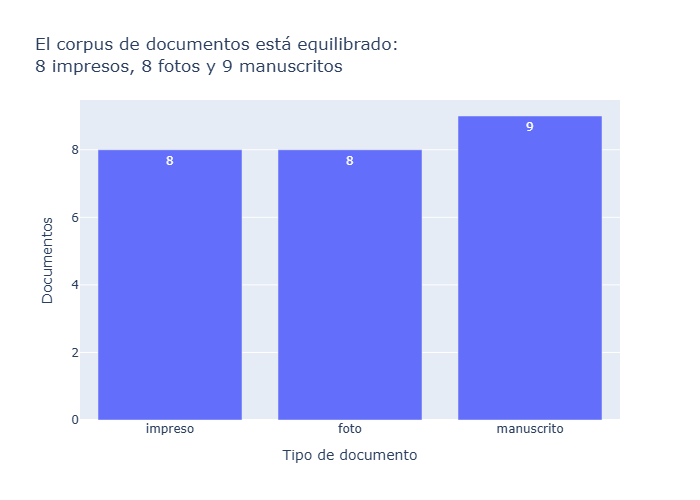

In [13]:
# Configuración de Plotly: interactivo en VS Code y, además, imagen PNG para que se vea en GitHub
import plotly.express as px
import plotly.io as pio
pio.renderers.default = "vscode+png"

conteo = documentos["tipo"].value_counts().reindex(["impreso", "foto", "manuscrito"]).reset_index()
fig = px.bar(conteo, x="tipo", y="count", text="count",
             labels={"tipo": "Tipo de documento", "count": "Documentos"},
             title="El corpus de documentos está equilibrado:<br>8 impresos, 8 fotos y 9 manuscritos")
fig.show()

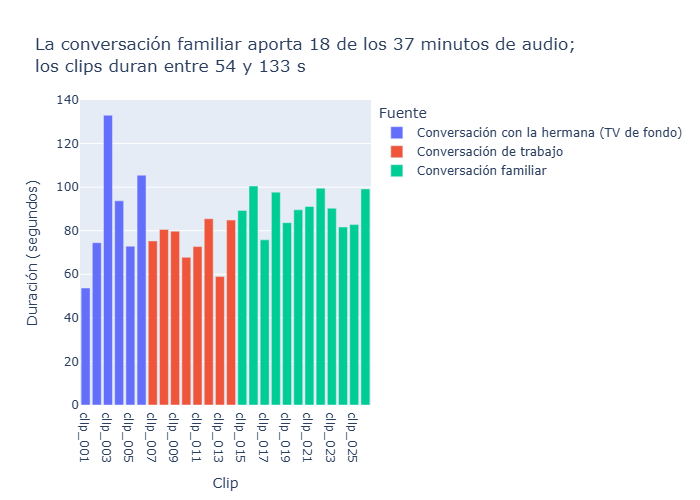

In [14]:
# Se agrega la fuente de cada clip según su grabación original
FUENTE_AUDIO = {"conversacion_trabajo.mp3": "Conversación de trabajo", "conversacion_familia.mp3": "Conversación familiar"}
clips["fuente"] = clips["original"].map(FUENTE_AUDIO).fillna("Conversación con la hermana (TV de fondo)")
minutos = clips.groupby("fuente")["duracion_seg"].sum() / 60

fig = px.bar(clips, x="id", y="duracion_seg", color="fuente",
             labels={"id": "Clip", "duracion_seg": "Duración (segundos)", "fuente": "Fuente"},
             title=f"La conversación familiar aporta {minutos['Conversación familiar']:.0f} de los "
                   f"{clips['duracion_seg'].sum() / 60:.0f} minutos de audio;<br>los clips duran entre "
                   f"{clips['duracion_seg'].min():.0f} y {clips['duracion_seg'].max():.0f} s")
fig.show()

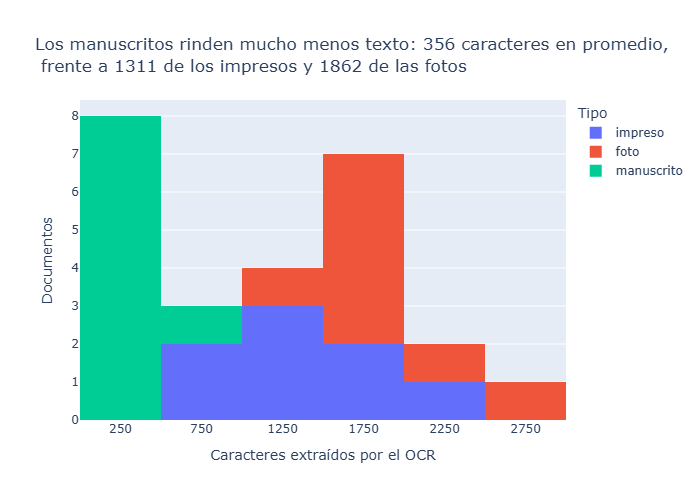

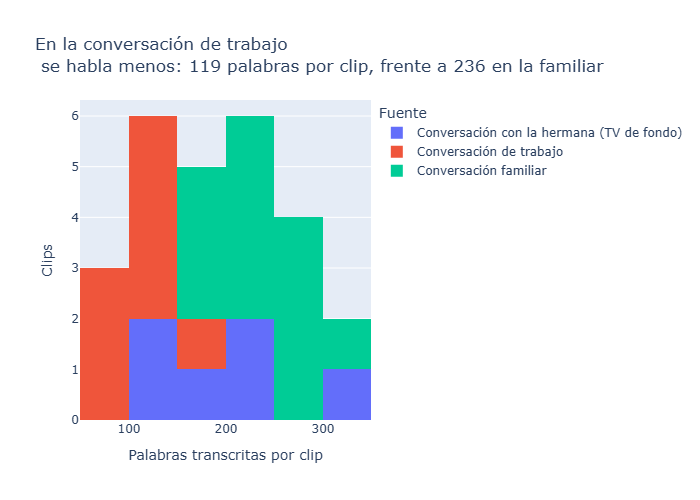

In [15]:
media_ocr = documentos.groupby("tipo")["caracteres"].mean()
fig = px.histogram(documentos, x="caracteres", color="tipo", nbins=12,
                   labels={"caracteres": "Caracteres extraídos por el OCR", "tipo": "Tipo"},
                   title=f"Los manuscritos rinden mucho menos texto: {media_ocr['manuscrito']:.0f} caracteres en promedio, "
                         f"<br> frente a {media_ocr['impreso']:.0f} de los impresos y {media_ocr['foto']:.0f} de las fotos")
fig.update_yaxes(title_text="Documentos")
fig.show()

media_asr = clips.groupby("fuente")["palabras"].mean()
fig = px.histogram(clips, x="palabras", color="fuente", nbins=10,
                   labels={"palabras": "Palabras transcritas por clip", "fuente": "Fuente"},
                   title=f"En la conversación de trabajo <br> se habla menos: {media_asr['Conversación de trabajo']:.0f} "
                         f"palabras por clip, frente a {media_asr['Conversación familiar']:.0f} en la familiar")
fig.update_yaxes(title_text="Clips")
fig.show()

## 1.7. Validación

*Mostrar los 3 documentos con OCR más largo y más corto y los 3 clips más largos y más cortos, verificando coherencia con los histogramas.*

Los resultados son coherentes con los histogramas: los textos OCR más largos son dos fotos de SERVIR (`doc_009`, `doc_014`) y una página de la tesis (`doc_003`), y los más cortos son tres manuscritos (`doc_019`, `doc_025`, `doc_021`), justamente la cola izquierda del histograma de caracteres. 

Sobre los audios, el clip más largo (`clip_003`, 133 s) es una grabación con la hermana que no se dividió, y el más corto (`clip_001`, 54 s) también; todos los clips de las conversaciones divididas duran entre 59 y 101 s.

In [16]:
# Validación: documentos y clips de los extremos, para comparar con los histogramas
cols_doc = ["id", "tipo", "caracteres", "confianza_ocr"]
print("Documentos con más texto OCR:"); display(documentos.nlargest(3, "caracteres")[cols_doc])
print("Documentos con menos texto OCR:"); display(documentos.nsmallest(3, "caracteres")[cols_doc])

cols_clip = ["id", "fuente", "duracion_seg", "palabras"]
print("Clips más largos:"); display(clips.nlargest(3, "duracion_seg")[cols_clip])
print("Clips más cortos:"); display(clips.nsmallest(3, "duracion_seg")[cols_clip])

Documentos con más texto OCR:


,id,tipo,caracteres,confianza_ocr
8,doc_009,foto,2724,0.994
2,doc_003,impreso,2143,0.992
13,doc_014,foto,2055,0.995


Documentos con menos texto OCR:


,id,tipo,caracteres,confianza_ocr
18,doc_019,manuscrito,200,0.921
24,doc_025,manuscrito,264,0.951
20,doc_021,manuscrito,274,0.834


Clips más largos:


,id,fuente,duracion_seg,palabras
2,clip_003,Conversación con la hermana (TV de fondo),133.0,322
5,clip_006,Conversación con la hermana (TV de fondo),105.5,225
15,clip_016,Conversación familiar,100.5,240


Clips más cortos:


,id,fuente,duracion_seg,palabras
0,clip_001,Conversación con la hermana (TV de fondo),53.7,143
12,clip_013,Conversación de trabajo,59.0,95
9,clip_010,Conversación de trabajo,67.8,91


## 1.8. Exportación

*Guardar datos/documentos.csv, datos/transcripciones.csv y datos/fuentes.csv (con id, modalidad, fuente_url, licencia y acceso o instrucciones de recuperación); mostrar los df.shape y las primeras 5 filas de los corpus. El archivo texto_referencia puede mantenerse vacío inicialmente y completarse en la Parte 2.*

In [17]:
# Exportación a datos/ (solo textos seudonimizados; los archivos originales quedan en datos/raw/, que no se publica)
URL_SERVIR = "https://cdn.www.gob.pe/uploads/document/file/1206414/Estudio-de-Gobiernos-Locales-2016-SERVIR.pdf"
LICENCIA_SERVIR = "Publicación institucional de SERVIR; uso académico citando la fuente"   # ajustar según la página legal

FUENTE_DOC = {
    "impreso": "Trabajo de licenciatura de la autora (documento propio, uso autorizado)",
    "foto": "SERVIR, Estudio de Gobiernos Locales 2016 (fotos propias de la publicación impresa)",
    "manuscrito": "Apuntes de clase de la autora (documento propio, uso autorizado)",
}
documentos["fuente"] = documentos["tipo"].map(FUENTE_DOC)
documentos["texto_referencia"] = ""      # se completa en la Parte 2
clips["texto_referencia"] = ""

COLUMNAS_DOC = ["id", "archivo", "tipo", "fuente", "texto_ocr", "modelo_ocr", "texto_referencia",
                "caracteres", "confianza_ocr"]
COLUMNAS_AUDIO = ["id", "archivo_audio", "duracion_seg", "idioma", "texto_asr", "modelo_asr", "n_hablantes",
                  "texto_referencia", "fuente", "palabras", "segundos_asr"]
documentos[COLUMNAS_DOC].to_csv("datos/documentos.csv", index=False, encoding="utf-8")
clips[COLUMNAS_AUDIO].to_csv("datos/transcripciones.csv", index=False, encoding="utf-8")

# Fuente, licencia y acceso de cada archivo
CONSENTIMIENTO = {
    "Conversación con la hermana (TV de fondo)": "consentimiento grabado aparte (autorizacion_hermana.mp3)",
    "Conversación de trabajo": "consentimiento verbal al inicio de clip_007",
    "Conversación familiar": "consentimiento verbal de las 4 personas al inicio de clip_015",
}
fuentes_doc = pd.DataFrame({
    "id": documentos["id"],
    "modalidad": "documento",
    "fuente_url": documentos["tipo"].map({"foto": URL_SERVIR}).fillna(""),
    "licencia": documentos["tipo"].map({"foto": LICENCIA_SERVIR}).fillna("Documento propio de la autora; uso autorizado"),
    "acceso": "Imagen no publicada (datos/raw/documentos/); se publica solo el texto OCR",
})
fuentes_audio = pd.DataFrame({
    "id": clips["id"],
    "modalidad": "audio",
    "fuente_url": "",
    "licencia": "Grabación propia con " + clips["fuente"].map(CONSENTIMIENTO),
    "acceso": "Audio no publicado (datos/raw/audio/); se publica solo la transcripción seudonimizada",
})
pd.concat([fuentes_doc, fuentes_audio], ignore_index=True).to_csv("datos/fuentes.csv", index=False, encoding="utf-8")

# Verificación: forma y primeras filas de cada CSV
for nombre in ["documentos", "transcripciones", "fuentes"]:
    tabla = pd.read_csv(f"datos/{nombre}.csv")
    print(f"datos/{nombre}.csv: {tabla.shape}")
    display(tabla.head())


datos/documentos.csv: (25, 9)


,id,archivo,tipo,fuente,texto_ocr,modelo_ocr,texto_referencia,caracteres,confianza_ocr
0,doc_001,datos/raw/documentos/doc_001.png,impreso,Trabajo de licenciatura de la autora (document...,área requiera realizar algún tipo de coordinac...,"PaddleOCR 3.7.0 (PP-OCRv6 medium, lang=es, ori...",NaN,1718,0.993
1,doc_002,datos/raw/documentos/doc_002.png,impreso,Trabajo de licenciatura de la autora (document...,"documentos administrativos, correos y llamadas...","PaddleOCR 3.7.0 (PP-OCRv6 medium, lang=es, ori...",NaN,855,0.996
2,doc_003,datos/raw/documentos/doc_003.png,impreso,Trabajo de licenciatura de la autora (document...,considerando que se ha digitalizado varias act...,"PaddleOCR 3.7.0 (PP-OCRv6 medium, lang=es, ori...",NaN,2143,0.992
3,doc_004,datos/raw/documentos/doc_004.png,impreso,Trabajo de licenciatura de la autora (document...,2.2.1. Evaluación de Formatos D100\nLa evaluac...,"PaddleOCR 3.7.0 (PP-OCRv6 medium, lang=es, ori...",NaN,1080,0.993
4,doc_005,datos/raw/documentos/doc_005.png,impreso,Trabajo de licenciatura de la autora (document...,Para el seguimiento de la subsanación de los F...,"PaddleOCR 3.7.0 (PP-OCRv6 medium, lang=es, ori...",NaN,1027,0.992


datos/transcripciones.csv: (26, 11)


,id,archivo_audio,duracion_seg,idioma,texto_asr,modelo_asr,n_hablantes,texto_referencia,fuente,palabras,segundos_asr
0,clip_001,datos/raw/audio/clip_001.wav,53.7,es,"[HABLANTE_1] [PERSONA_1], cuéntame tu experien...","faster-whisper 1.2.1 small (int8, CPU, VAD act...",2,NaN,Conversación con la hermana (TV de fondo),143,54.1
1,clip_002,datos/raw/audio/clip_002.wav,74.5,es,"[HABLANTE_1] Sobre tu experiencia en Uruguay, ...","faster-whisper 1.2.1 small (int8, CPU, VAD act...",2,NaN,Conversación con la hermana (TV de fondo),180,85.6
2,clip_003,datos/raw/audio/clip_003.wav,133.0,es,[HABLANTE_1] Y sobre tu experiencia viviendo e...,"faster-whisper 1.2.1 small (int8, CPU, VAD act...",2,NaN,Conversación con la hermana (TV de fondo),322,179.1
3,clip_004,datos/raw/audio/clip_004.wav,93.7,es,[HABLANTE_1] ¿Y qué habilidades has aprendido ...,"faster-whisper 1.2.1 small (int8, CPU, VAD act...",2,NaN,Conversación con la hermana (TV de fondo),216,175.7
4,clip_005,datos/raw/audio/clip_005.wav,72.9,es,"[HABLANTE_1] ¡[PERSONA_1], te acuerdas cuando ...","faster-whisper 1.2.1 small (int8, CPU, VAD act...",2,NaN,Conversación con la hermana (TV de fondo),121,84.0


datos/fuentes.csv: (51, 5)


,id,modalidad,fuente_url,licencia,acceso
0,doc_001,documento,NaN,Documento propio de la autora; uso autorizado,Imagen no publicada (datos/raw/documentos/); s...
1,doc_002,documento,NaN,Documento propio de la autora; uso autorizado,Imagen no publicada (datos/raw/documentos/); s...
2,doc_003,documento,NaN,Documento propio de la autora; uso autorizado,Imagen no publicada (datos/raw/documentos/); s...
3,doc_004,documento,NaN,Documento propio de la autora; uso autorizado,Imagen no publicada (datos/raw/documentos/); s...
4,doc_005,documento,NaN,Documento propio de la autora; uso autorizado,Imagen no publicada (datos/raw/documentos/); s...
